# Семинар 12. Обработка речи: спектрограммы, ASR и TTS

Сравниваем спектральные представления звука, распознаем речь моделью Whisper и разбираем Duration Predictor и Length Regulator в FastSpeech. В конце слушаем готовые примеры синтеза с разным темпом и двумя способами восстановления звука. MFCC и аугментации вынесены в бонус.

В Google Colab выберите среду с GPU.

In [ ]:
from pathlib import Path
import sys
import zipfile

archive_path = Path("Семинар_неделя_12.zip")
data_file = Path("data/poemi_12_pushkin_0001.wav")

if not data_file.is_file():
    if not archive_path.is_file():
        if "google.colab" not in sys.modules:
            raise FileNotFoundError(
                "Положите Семинар_неделя_12.zip рядом с ноутбуком "
                "и запустите ячейку еще раз."
            )

        from google.colab import files

        uploaded = files.upload()
        zip_files = [
            Path(name)
            for name in uploaded
            if zipfile.is_zipfile(name)
        ]

        if not zip_files:
            raise FileNotFoundError("Загрузите ZIP-архив семинара.")

        archive_path = zip_files[0]

    with zipfile.ZipFile(archive_path) as archive:
        for item in archive.infolist():
            path = Path(item.filename)
            if (
                path.parts
                and path.parts[0] == "data"
                and ".." not in path.parts
            ):
                archive.extract(item)

    if not data_file.is_file():
        raise FileNotFoundError(
            "В архиве отсутствует data/poemi_12_pushkin_0001.wav. "
            "Проверьте, что выбран полный архив семинара 12."
        )

print("Данные готовы.")

In [ ]:
%pip install -q --disable-pip-version-check "torch==2.6.0" "torchaudio==2.6.0" "torchvision==0.21.0" "transformers==4.50.3" "huggingface-hub==0.36.2" "librosa==0.11.0" "soundfile==0.14.0" "numpy>=2,<3" "scipy>=1.13,<2" "matplotlib>=3.9,<4" "seaborn==0.13.2" "ipywidgets>=8.1,<9"

In [ ]:
import os


import torch
import torchaudio

import librosa

import numpy as np

from IPython.display import display, Audio

import matplotlib_inline
import matplotlib.pyplot as plt

matplotlib_inline.backend_inline.set_matplotlib_formats('png')
from torch import nn
from torch.nn.utils.rnn import pad_sequence
from dataclasses import dataclass
import random
random.seed(42)
np.random.seed(42)
torch.manual_seed(42)

In [ ]:
if torch.cuda.is_available():
    device = torch.device('cuda', 0)
else:
    device = torch.device('cpu')

## 1. Спектральные признаки

#### Основные характеристики цифрового сигнала
* **Sample rate (SR)** - количество измерений сигнала в секунду (например, $8$кГц, $22,05$кГц, $44,1$кГц)
* **Sample size** - количество битов на одно измерение (например, $8$, $16$, $24$, $32$ бита)
* **Количество каналов** - сколько сигналов мы записываем параллельно (например, моно ($1$), стерео ($2$))
* Формат хранения
    * Без сжатия: WAV, ...
    * Сжатие без потерь: FLAC, ALAC, ...
    * Сжатие с потерями: MP3, Opus, ...

In [ ]:
Audio(filename='data/poemi_12_pushkin_0001.wav')

In [ ]:
metadata = torchaudio.info('data/poemi_12_pushkin_0001.wav')
print(metadata)

In [ ]:
signal, sample_rate = torchaudio.load('data/poemi_12_pushkin_0001.wav')
signal, signal.shape, sample_rate

In [ ]:
signal = signal.mean(dim=0)

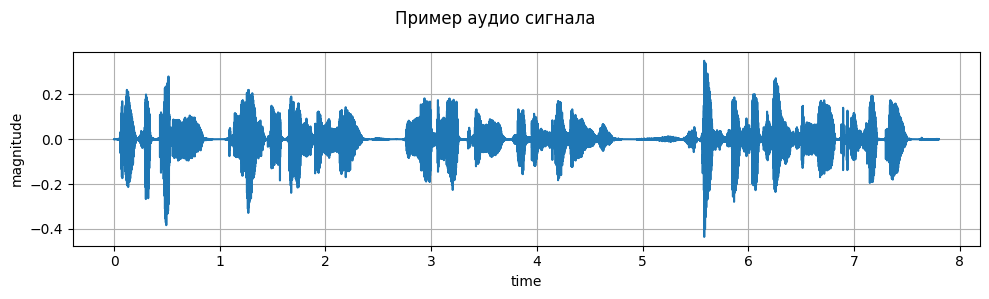

In [ ]:
fig, ax = plt.subplots(1, 1, figsize=(10, 3))

ax.plot(np.arange(signal.shape[0]) / sample_rate, signal.cpu().numpy())

ax.grid(True)

ax.set_xlabel('time')
ax.set_ylabel('magnitude')

fig.suptitle('Пример аудио сигнала')
fig.tight_layout()
plt.show()

### Преобразование Фурье

Преобразование Фурье (FT) - это математическая формула, которая позволяет разложить сигнал на его отдельные частоты и соответствующие им амплитуды.

Прямое (**time -> frequency**), где $\omega$ - частота:

$$
F(\omega)=\int\limits_{-\infty}^{\infty}f(t)e^{-2\pi it\omega}\,dt
$$

Дискретное преобразование Фурье:
$$
X_k = \sum_{n=0}^{N-1}x_ne^{-i \frac{2\pi}{N}kn}
$$

Каждое комплексное $X_k=|X_k|e^{i\phi_k}$ нам дает
- мощность частоты $|X_k|^2$
- фазу $\phi_k$

In [ ]:
spectrum = torch.fft.rfft(signal)
spectrum.dtype, spectrum.shape

In [ ]:
spectrogram = spectrum.abs().pow(2)
spectrogram.shape

In [ ]:
fig, ax = plt.subplots(1, 1, figsize=(10, 3))

ax.plot(torch.log(spectrogram).cpu().numpy())

ax.grid(True)

ax.set_xlabel('Frequency bin')
ax.set_ylabel('ln(power)')

fig.suptitle('Пример спектра сигнала')
fig.tight_layout()
plt.show()

##### Short-Time Fourier Transform

Коротковременное преобразование Фурье (Short-Time Fourier Transform, STFT) можно рассматривать как развитие классического дискретного преобразования Фурье (DFT/FFT) для анализа не всего сигнала сразу, а его отдельных коротких фрагментов (окон).

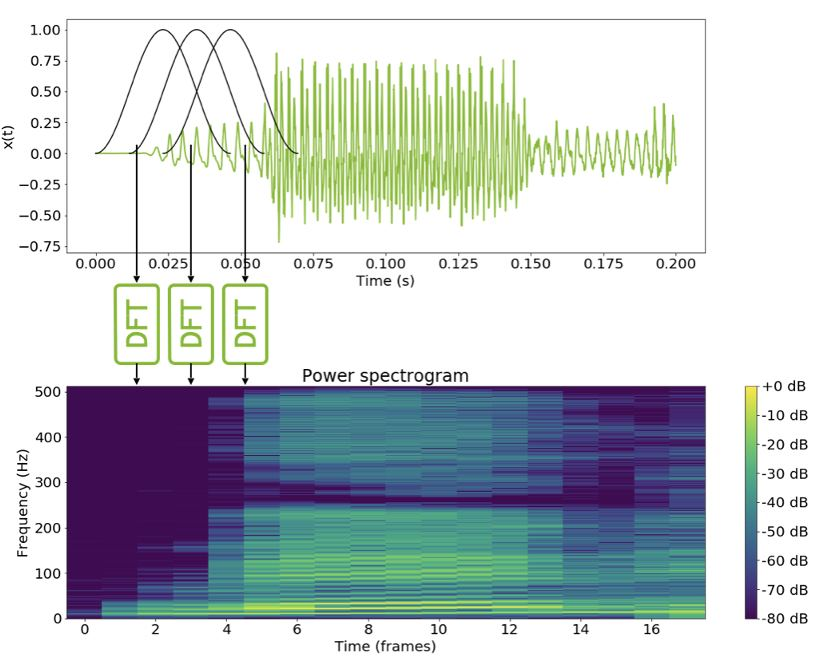

Полученные при вычислении STFT коэффициенты наиболее удобно визуализировать в виде спектрограммы:

- Горизонтальная ось - время или номер окна

- Вертикальная ось - частота или индекс спектральной компоненты  k

- Интенсивность (цвет или яркость) - мощность $|X(n,k)|^2$ , которая показывает, насколько сильна частота в текущем временном фрагменте

Это дает двумерное представление «частота-время», из которого можно видеть, как распределение частот в сигнале меняется с течением времени.

In [ ]:
# Альтернативно можно использовать torch.stft
n_fft = 400

spec = torchaudio.transforms.Spectrogram(n_fft=n_fft, power=2)
spectrogram = spec(signal)

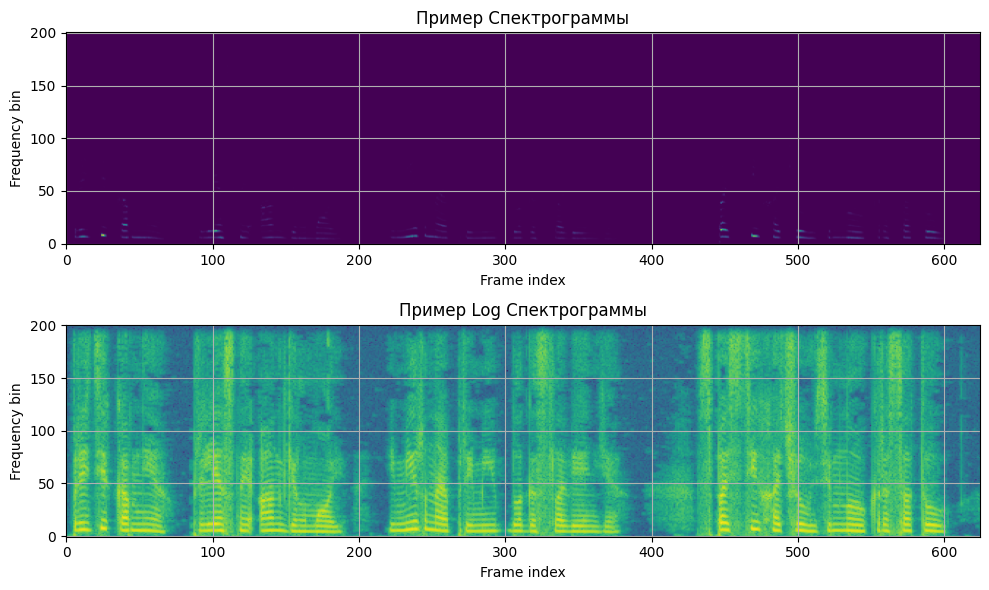

In [ ]:
fig, axes = plt.subplots(2, 1, figsize=(10, 6))

axes[0].imshow(spectrogram.cpu().numpy(), aspect='auto', origin='lower')
axes[1].imshow(torch.log(spectrogram).cpu().numpy(), aspect='auto', origin='lower')

axes[0].grid(True)
axes[1].grid(True)

axes[0].set_title('Пример Спектрограммы')
axes[1].set_title('Пример Log Спектрограммы')

axes[0].set_xlabel('Frame index')
axes[1].set_xlabel('Frame index')
axes[0].set_ylabel('Frequency bin')
axes[1].set_ylabel('Frequency bin')

fig.tight_layout()
plt.show()

* Преимущества - более сжатое представление во временной области
* Однако, в частотной области все еще много отсчетов

### Mel-спектрограмма

Так как человек лучше различает между собой низкие частоты, то при сжатии в частотной области стоит уделить большее внимание нижней части спектра.

In [ ]:
n_mels = 64
mel_spec = torchaudio.transforms.MelSpectrogram(n_fft=n_fft, power=2, n_mels=n_mels, sample_rate=sample_rate)
mel_spectrogram = mel_spec(signal)

# Или альтернативно:
mel_filters = torchaudio.functional.melscale_fbanks(
    int(n_fft // 2 + 1),
    n_mels=n_mels,
    f_min=0.0,
    f_max=sample_rate / 2.0,
    sample_rate=sample_rate,
    norm=None,
)

mel_spectrogram_other = mel_filters.T @ spectrogram

In [ ]:
mel_filters.shape, spectrogram.shape

(torch.Size([201, 64]), torch.Size([201, 625]))

In [ ]:
mel_filters.shape

torch.Size([201, 64])

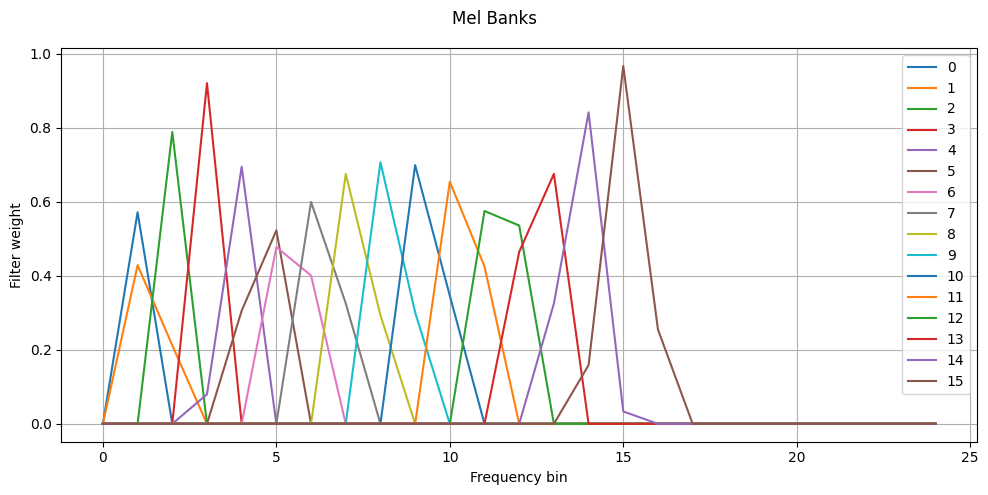

In [ ]:
fig, ax = plt.subplots(1, 1, figsize=(10, 5))

for idx in range(0, mel_filters.shape[1] // 4, 1):
    ax.plot(mel_filters[:, idx].cpu().numpy()[:25], label=str(idx))

ax.set_xlabel('Frequency bin')
ax.set_ylabel('Filter weight')

ax.legend()
ax.grid(True)

fig.suptitle('Mel Banks')
fig.tight_layout()
plt.show()

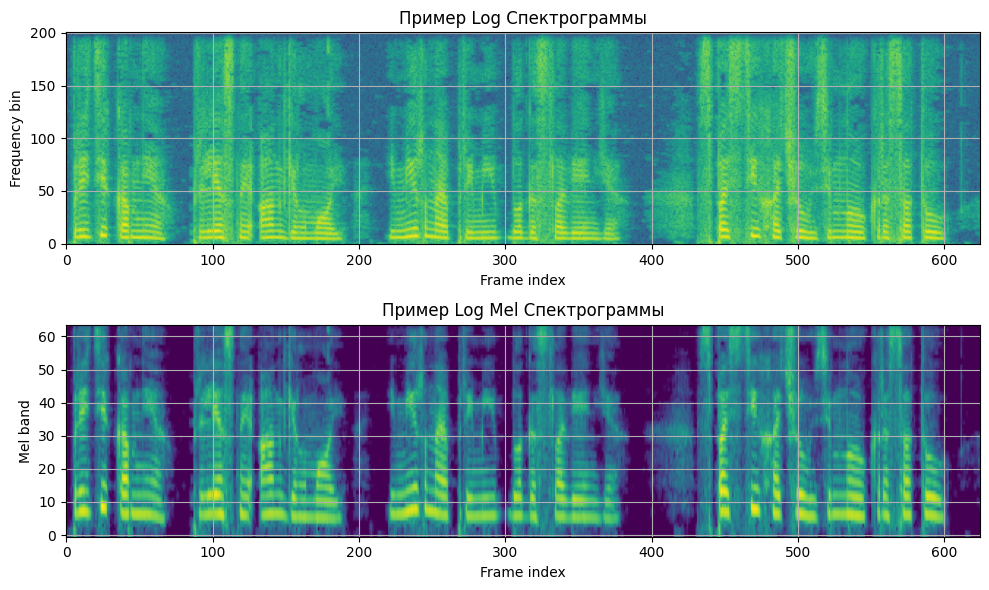

In [ ]:
fig, axes = plt.subplots(2, 1, figsize=(10, 6))

axes[0].imshow(torch.log(spectrogram).cpu().numpy(), aspect='auto', origin='lower')
axes[1].imshow(torch.log(mel_spectrogram.clamp(min=1e-5)).cpu().numpy(), aspect='auto', origin='lower')

axes[0].grid(True)
axes[1].grid(True)

axes[0].set_title('Пример Log Спектрограммы')
axes[1].set_title('Пример Log Mel Спектрограммы')

axes[0].set_xlabel('Frame index')
axes[1].set_xlabel('Frame index')
axes[0].set_ylabel('Frequency bin')
axes[1].set_ylabel('Mel band')

fig.tight_layout()
plt.show()

## 2. Распознавание речи

### CTC Loss

Connectionist Temporal Classification (CTC).

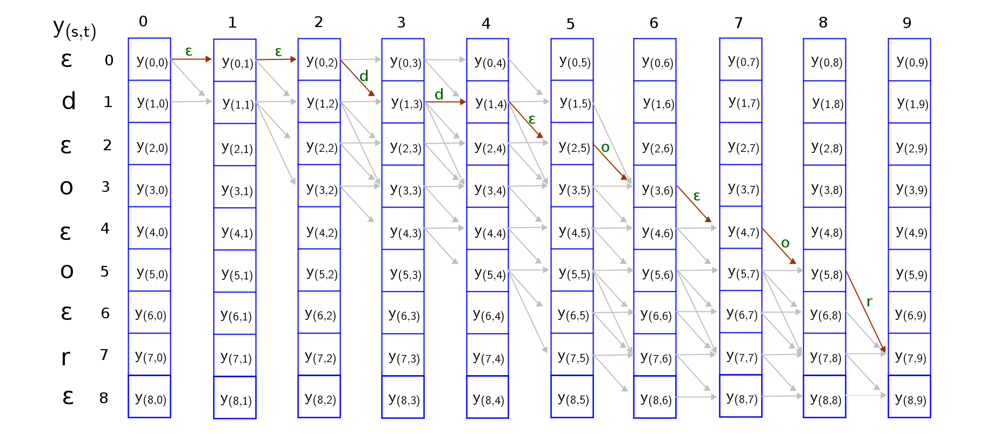

[Graves et al., 2006](https://www.cs.toronto.edu/~graves/icml_2006.pdf).

1. Пример:
  - pred: brother ma cartle brother kiff
  - target: brother mac ardle brother keogh
2. Пример:
  - pred: chapter three as master wihes thre secons befor the rrivale a jaby hobson's letter
  - target: chapter three as master wishes three seconds before the arrival of j b hobson's letter

### Метрики

Популярный подход - использовать расстояние Левенштейна:
1. **WER** - word-level (word level levenshtein)
2. **CER** - char error rate (char level levenshtein)

### Whisper: encoder-decoder

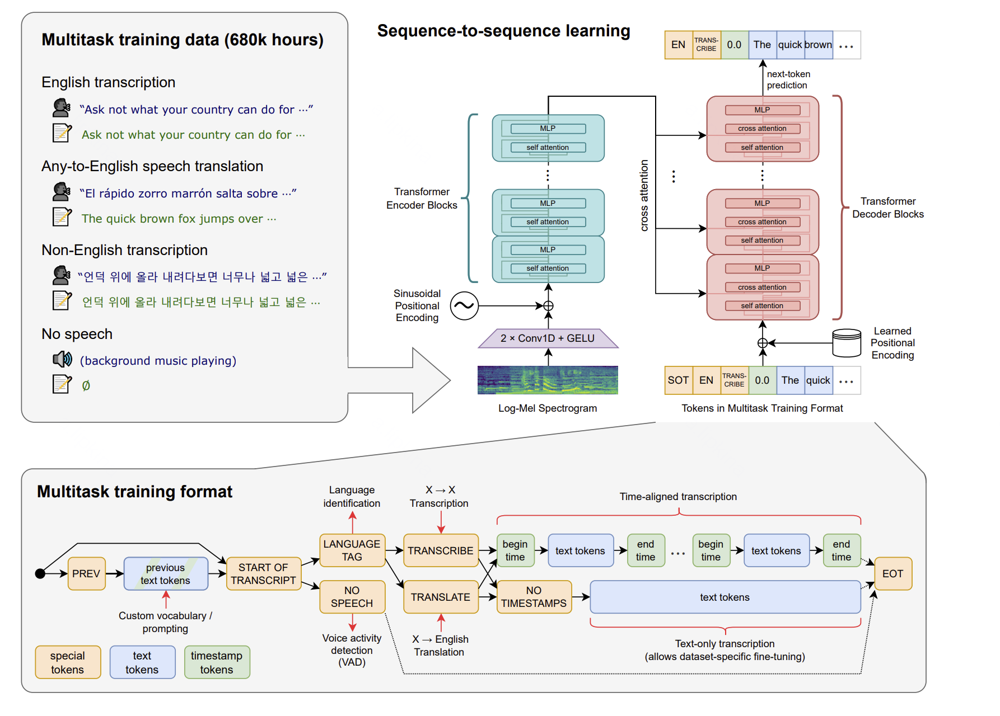

In [ ]:
from transformers import WhisperProcessor, WhisperForConditionalGeneration

processor = WhisperProcessor.from_pretrained("openai/whisper-large", revision="4ef9b41f0d4fe232daafdb5f76bb1dd8b23e01d7")
asr_model = WhisperForConditionalGeneration.from_pretrained("openai/whisper-large", revision="4ef9b41f0d4fe232daafdb5f76bb1dd8b23e01d7")
asr_model.config.forced_decoder_ids = None
asr_model.generation_config.forced_decoder_ids = None
asr_model = asr_model.to(device).eval()

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


preprocessor_config.json: 0.00B [00:00, ?B/s]

tokenizer_config.json: 0.00B [00:00, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

... (2 outputs left out)

special_tokens_map.json: 0.00B [00:00, ?B/s]

config.json: 0.00B [00:00, ?B/s]

model.safetensors:   0%|          | 0.00/6.17G [00:00<?, ?B/s]

generation_config.json: 0.00B [00:00, ?B/s]

In [ ]:
audio_tensor, sample_rate = torchaudio.load('data/poemi_12_pushkin_0001.wav')
input_features = processor(audio_tensor.mean(dim=0), sampling_rate=sample_rate, return_tensors="pt", return_attention_mask=True)

with torch.inference_mode():
    predicted_ids = asr_model.generate(
        input_features.input_features.to(device),
        attention_mask=input_features.attention_mask.to(device),
        task="transcribe", language="ru",
    )
transcription = processor.batch_decode(predicted_ids, skip_special_tokens=False)
transcription

[' Приди ко мне, прелестный ангел мой, И мирно опрями благословенье. Спасти хочу земную красоту,']

## 3. Восстановление сигнала: фаза и Griffin-Lim

In [ ]:
import librosa
import librosa.display as ld

# Для отображение Audio в ноутбуке
from IPython.display import Audio as Audio_jp

In [ ]:
def show_audio(signal, normalize=True):
    return Audio_jp(data=signal[0], rate=signal[1], normalize=normalize)

In [ ]:
buzzer = librosa.load('data/buzzer_saved.wav', sr=None)

Здесь используется звуковой фрагмент, сохраненный в исходном ноутбуке. Сравниваются восстановление без исходной фазы и алгоритм Griffin-Lim.

In [ ]:
librosa.stft(buzzer[0]).shape

(1025, 192)

<font color='DarkOrange'>**Вопрос (?)**</font> Почему 192? Что это такое?

#### Ответ

In [ ]:
hop_len = 2048 // 4
1 + buzzer[0].shape[0] // hop_len

192

### Амплитуда и фаза

На самом деле возвращаются комплексные числа!

In [ ]:
librosa.stft(buzzer[0])

array([[-1.9070379e+00+0.0000000e+00j, -9.9466527e-01+0.0000000e+00j,
        -1.1916071e-01+0.0000000e+00j, ...,
        -5.7855141e-03+0.0000000e+00j,  2.3005348e-01+0.0000000e+00j,
         4.6580639e-01+0.0000000e+00j],
       [ 1.9193360e+00-2.3220694e-03j, -2.0353131e-02+9.1732138e-01j,
         1.2269762e-01-3.8330089e-02j, ...,
         1.6312417e-02+1.8663947e-02j, -9.4171222e-03+2.1897064e-01j,
        -4.5411235e-01+1.6330047e-02j],
       [-1.9162433e+00+4.1031167e-02j,  1.0450063e+00-3.3902466e-02j,
        -1.2257996e-01+4.4530701e-02j, ...,
        -3.7494549e-03-1.5772961e-02j, -1.9467336e-01+1.6955018e-02j,
         4.3190110e-01-4.6117906e-02j],
       ...,
       [ 5.8289170e-03+3.3246531e-04j, -2.6773098e-03-4.2614696e-04j,
        -3.6117347e-04+3.8054073e-04j, ...,
         4.6798294e-05+6.1205195e-05j, -2.1073460e-03-3.8843177e-04j,
         4.5717005e-03+8.9365424e-04j],
       [-6.0641849e-03-2.8642814e-04j, -2.4007207e-04+3.3121838e-03j,
         2.1081379e-04

Результатом дискретного преобразования Фурье (ДПФ) является массив комплексных чисел, который включает действительную и мнимую части. Для получения амплитудной информации из спектрограммы можно использовать функцию np.abs(dft). Аргумент комплексного числа задает фазу соответствующей компоненты, однако в задачах машинного обучения он зачастую игнорируется.

На основе преобразования фурье можно отобразить так называемую спектрограмму

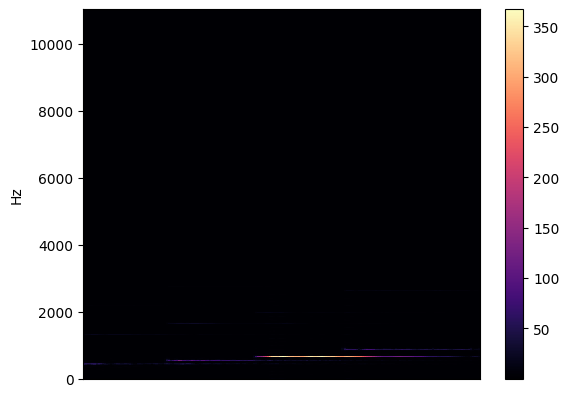

In [ ]:
librosa.display.specshow(np.abs(librosa.stft(buzzer[0])), y_axis='linear')
plt.colorbar()

Для облегчения просмотра преобразуем значения амплитуды в децибельную шкалу.

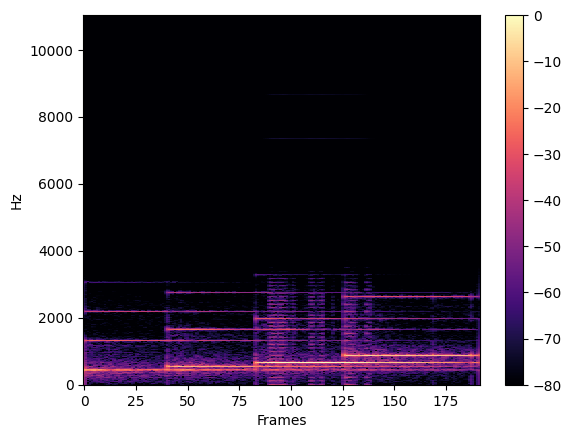

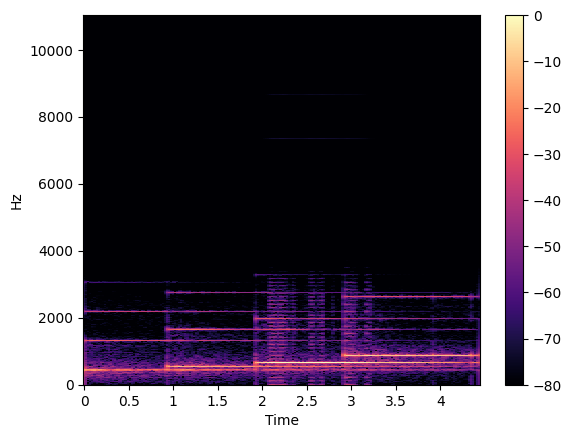

In [ ]:
D = librosa.amplitude_to_db(np.abs(librosa.stft(buzzer[0])), ref=np.max)
librosa.display.specshow(D, y_axis='linear', x_axis='frames')
plt.colorbar()
plt.show()
librosa.display.specshow(D, y_axis='linear', x_axis='time')
plt.colorbar()
plt.show()

In [ ]:
D.shape

(1025, 192)

In [ ]:
D

array([[-45.687256, -51.3409  , -69.77178 , ..., -80.      , -64.05786 ,
        -57.930332],
       [-45.631416, -52.041874, -69.11331 , ..., -80.      , -64.4787  ,
        -58.14556 ],
       [-45.643436, -50.907494, -68.98769 , ..., -80.      , -65.475494,
        -58.537518],
       ...,
       [-80.      , -80.      , -80.      , ..., -80.      , -80.      ,
        -80.      ],
       [-80.      , -80.      , -80.      , ..., -80.      , -80.      ,
        -80.      ],
       [-80.      , -80.      , -80.      , ..., -80.      , -80.      ,
        -80.      ]], shape=(1025, 192), dtype=float32)

### Обратное преобразование

In [ ]:
buzzer_inv = librosa.istft(librosa.db_to_amplitude(D))

In [ ]:
buzzer_inv

array([ 6.7088986e-05,  5.3660584e-05,  3.9245162e-05, ...,
       -3.3297969e-05, -2.2951193e-05, -1.1648759e-05],
      shape=(97792,), dtype=float32)

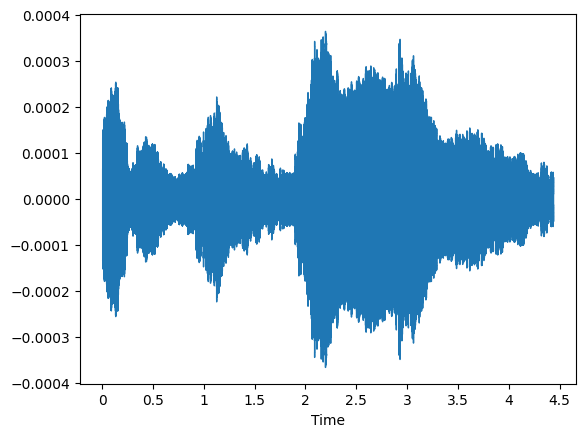

In [ ]:
ld.waveshow(buzzer_inv, sr=buzzer[1])

In [ ]:
show_audio(buzzer)

In [ ]:
show_audio((buzzer_inv, buzzer[1]))

Звук стал более шумным.. Решение - пытаться восстановить фазы, например, алгоритмом Гриффина-Лима или специальными вокодерами

In [ ]:
buzzer_inv2 = librosa.griffinlim(librosa.db_to_amplitude(D), random_state=42)

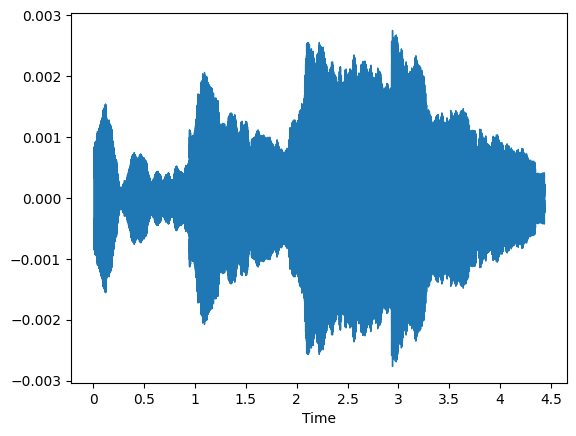

In [ ]:
ld.waveshow(buzzer_inv2, sr=buzzer[1])

In [ ]:
show_audio((buzzer_inv2, buzzer[1]))

## 4. Длительности в FastSpeech

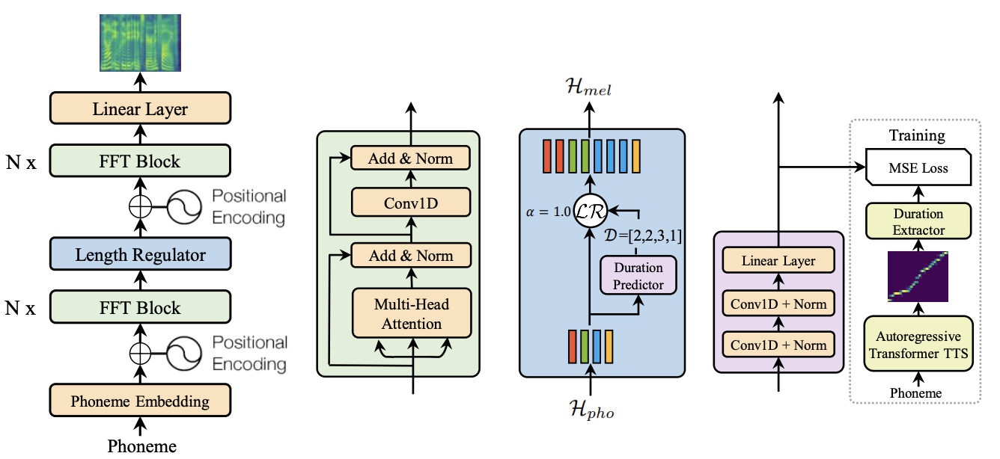

[Источник](https://arxiv.org/abs/1905.09263)

#### Вопрос

Зачем в FFT-блоке FastSpeech используется свертка вместо полносвязного FFN?

#### Ответ

Свертка с ядром больше 1 объединяет признаки соседних позиций. Полносвязный FFN обрабатывает каждую позицию отдельно. Дальние зависимости в FFT-блоке по-прежнему учитывает self-attention.

### Параметры модели

In [ ]:
# Конфиг для модели
@dataclass
class FastSpeechConfig:
    vocab_size = 300 # Размер словаря уникальных символов
    max_seq_len = 3000 # Максимальная длина последовательности в символах

    # Размерности блоков
    # Блок обработки входной последоватнльности из токенов текста
    encoder_dim = 256
    encoder_n_layer = 4
    encoder_head = 2
    encoder_conv1d_filter_size = 1024

    # Блок обработки последовательности после дублирования токенов на основании предсказания их длины.
    decoder_dim = 256
    decoder_n_layer = 4
    decoder_head = 2
    decoder_conv1d_filter_size = 1024

    # Свертки внутри трансформера
    fft_conv1d_kernel = (9, 1) # Ядро 1-ой и 2-ой свертки
    fft_conv1d_padding = (4, 0) # Паддинг 1-ой и 2-ой свертки

    # Блок предсказания длины произношения каждого токена
    duration_predictor_filter_size = 256
    duration_predictor_kernel_size = 3
    dropout = 0.1

    # Индексы служебных токенов
    PAD = 0
    UNK = 1
    BOS = 2
    EOS = 3

    # Названия токенов
    PAD_WORD = '<blank>'
    UNK_WORD = '<unk>'
    BOS_WORD = '<s>'
    EOS_WORD = '</s>'


model_config = FastSpeechConfig()

### Length Regulator

### Duration Predictor

Чтобы изменить длину входа в токенах и "раздублировать" его до длины входа в столбиках Мел-спектрограммы, надо предсказать, сколько "звучит" каждый токен. Это можно сделать с помощью отдельного выхода нейросети.

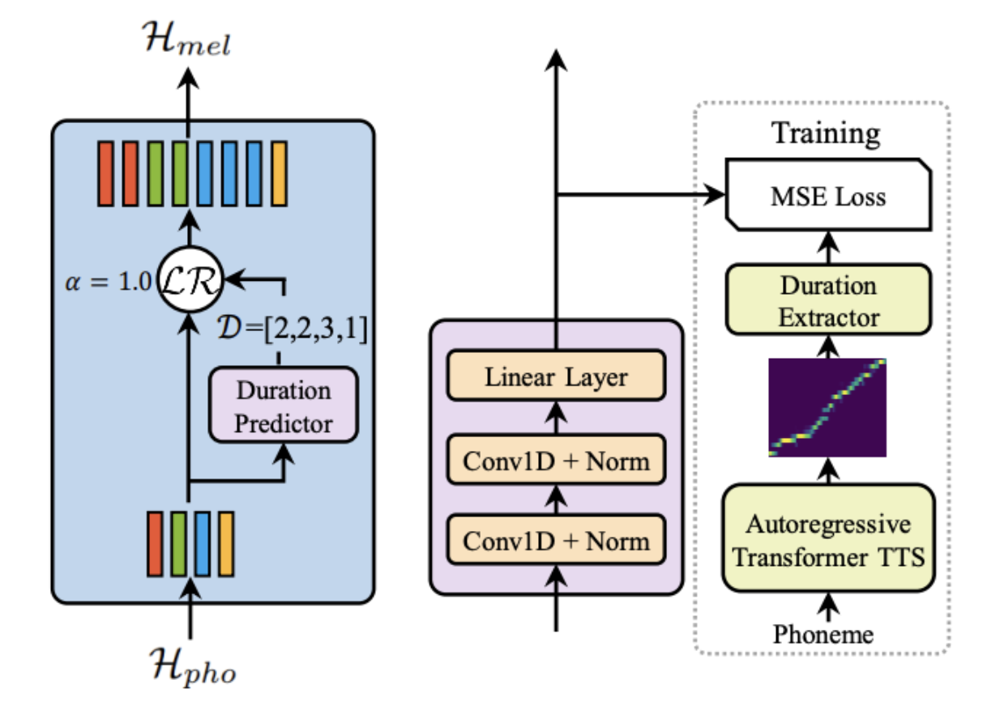

Отдельный блок для транспонирования, чтобы можно было удобно положить в `nn.Sequential`.

In [ ]:
class Transpose(nn.Module):
    def __init__(self, dim_1, dim_2):
        super().__init__()
        self.dim_1 = dim_1
        self.dim_2 = dim_2

    def forward(self, x):
        return x.transpose(self.dim_1, self.dim_2)

Сам предиктор имеет простую структуру: две свертки и линейный слой. В этой учебной реализации ReLU на выходе обеспечивает неотрицательность предсказанной длительности; предсказывается длительность напрямую, без логарифмирования.

In [ ]:
class DurationPredictor(nn.Module):
    """ Duration Predictor """

    def __init__(self, model_config: FastSpeechConfig):
        super(DurationPredictor, self).__init__()

        self.input_size = model_config.encoder_dim
        self.filter_size = model_config.duration_predictor_filter_size
        self.kernel = model_config.duration_predictor_kernel_size
        self.conv_output_size = model_config.duration_predictor_filter_size
        self.dropout = model_config.dropout

        self.conv_net = nn.Sequential(
            # Транспонируем, чтобы сворачивать по времени
            Transpose(-1, -2),
            # Свертка 1
            nn.Conv1d(
                self.input_size, self.filter_size,
                kernel_size=self.kernel, padding=1
            ),
            # Транспонируем обратно, для LayerNorm по последней размерности признаков
            Transpose(-1, -2),
            nn.LayerNorm(self.filter_size),
            nn.ReLU(),
            nn.Dropout(self.dropout),
            # И опять транспонирвем для свертки 2
            Transpose(-1, -2),
            nn.Conv1d(
                self.filter_size, self.filter_size,
                kernel_size=self.kernel, padding=1
            ),
            Transpose(-1, -2),
            nn.LayerNorm(self.filter_size),
            nn.ReLU(),
            nn.Dropout(self.dropout)
        )

        # Приводим к одному выходу, чтобы предсказывать продолжительность (одно число)
        self.linear_layer = nn.Linear(self.conv_output_size, 1)
        self.relu = nn.ReLU()

    def forward(self, encoder_output):
        encoder_output = self.conv_net(encoder_output)

        out = self.linear_layer(encoder_output)
        out = self.relu(out)
        out = out.squeeze(-1)
        return out

Проверка размерностей на случайных входных векторах и случайно инициализированных весах.

In [ ]:
dur_predictor = DurationPredictor(model_config)

inp_tensor = torch.rand(
    4, # batch_size
    12, #seq_len
    model_config.encoder_dim,
    dtype=torch.float32
)

dur_prediction = dur_predictor(inp_tensor)

In [ ]:
dur_prediction

tensor([[0.0000, 0.0000, 0.5249, 0.0594, 0.1760, 0.1555, 0.6192, 0.0055, 0.1903,
         0.0000, 0.0000, 0.1369],
        [0.2280, 0.0000, 0.0000, 0.2552, 0.0572, 0.2094, 0.3958, 0.0802, 0.5600,
         0.1140, 0.0000, 0.3592],
        [0.0000, 0.3746, 0.2211, 0.2314, 0.2561, 0.0000, 0.0000, 0.2121, 0.1299,
         0.2730, 0.0000, 0.3910],
        [0.0000, 0.0000, 0.2710, 0.4993, 0.3251, 0.1899, 0.0443, 0.0000, 0.3263,
         0.0618, 0.0921, 0.0000]], grad_fn=<SqueezeBackward1>)

### Задание: LengthRegulator

Наконец, соберем это в большой класс Length Regulator.

Этот модуль решает задачу: Преобразовать последовательность символов (текста) в последовательность той же длины, что и спектрограмма, используя информацию о том, сколько мел-фреймов должен занимать каждый символ.

Это нужно, потому что:

* Энкодер выдает по одному скрытому состоянию на символ -> [B, L, H].

* Декодер ожидает вход той же длины, что и целевая спектрограмма -> [B, T, H], где T >> L.

`LengthRegulator` "растягивает" эмбеддинги символов в соответствии с их длительностью произношения, чтобы выход энкодера подошел по размерностям на вход декодера.

Итак, в этом задании тебе надо реализовать класс блока `LengthRegulator`, а именно:
1. Раздублировать векторы в соответствии с длительностями;
2. При обучении использовать целевые длительности для размножения входа, а предсказания вернуть для функции потерь;
3. Если инферим модель, то после предсказания длины надо ее округлить до ближайшего целого числа, раздублировать вход по длине предсказаний, и потом получить индексы для позиционных эмбеддингов.

Больше подробностей в коде.

#### Твое решение

```python
class LengthRegulator(nn.Module):
    """ Length Regulator """

    def __init__(self, model_config):
        super(LengthRegulator, self).__init__()
        self.duration_predictor = DurationPredictor(model_config)

    # Каждый токен размножаем в соответствии с его длительностью
    def LR(self, x, durations, mel_max_length=None):
        out = []
        for b in range(x.size(0)):
            expanded = torch.repeat_interleave(
                x[b],
                durations[b].clamp(min=0),
                dim=0
            )
            out.append(expanded)

        out = pad_sequence(out, batch_first=True)

        if mel_max_length is not None:
            out = out[:, :mel_max_length]

        return out

    def forward(self, x, alpha=1.0, target=None, mel_max_length=None):
        '''
        alpha - регулировка темпа речи
        '''

        # Получаем предсказание длины произношения каждого токена
        duration_predictor_output = self.duration_predictor(x)

        # Если обучаеся, то предсказываем продолжительность звучания и возвращаем ее для передачи в loss
        if target is not None:
            output = # Получаем раздублированный вход
            return output, duration_predictor_output
        else:
            # Получаем предсказание продолжительности и округляем до ближайшего целого числа
            duration_predictor_output = # Округляем до ближайшего целого числа предсказание длительности произношения
            output = # Получаем раздублированный вход
            # Также делаем позиционные индексы mel спеки для декодера (их же не было, мы только что сгенерировали спеку)
            mel_pos = # Получаем позиционные индексы

            return output, mel_pos
```

#### Решение

In [ ]:
class LengthRegulator(nn.Module):
    """ Length Regulator """

    def __init__(self, model_config):
        super(LengthRegulator, self).__init__()
        self.duration_predictor = DurationPredictor(model_config)

    # Каждый токен размножаем в соответствии с его длительностью
    def LR(self, x, durations, mel_max_length=None):
        out = []
        for b in range(x.size(0)):
            expanded = torch.repeat_interleave(
                x[b],
                durations[b].clamp(min=0),
                dim=0
            )
            out.append(expanded)

        out = pad_sequence(out, batch_first=True)

        if mel_max_length is not None:
            out = out[:, :mel_max_length]

        return out

    def forward(self, x, alpha=1.0, target=None, mel_max_length=None):
        '''
        alpha - регулировка темпа речи
        '''

        # Получаем предсказание длины произношения каждого токена
        duration_predictor_output = self.duration_predictor(x)

        # Если обучаеся, то предсказываем продолжительность звучания и возвращаем ее для передачи в loss
        if target is not None:
            output = self.LR(x, target, mel_max_length)
            return output, duration_predictor_output
        else:
            # Получаем предсказание продолжительности и округляем до ближайшего целого числа
            duration_predictor_output = (duration_predictor_output * alpha + 0.5).int()
            output = self.LR(x, duration_predictor_output, mel_max_length)
            # Также делаем позиционные индексы mel спеки для декодера (их же не было, мы только что сгенерировали спеку)
            mel_pos = torch.arange(1, output.size(1) + 1, device=x.device, dtype=torch.long).unsqueeze(0).expand(x.size(0), -1)
            mel_pos = mel_pos.masked_fill(mel_pos > duration_predictor_output.sum(dim=1, keepdim=True), 0)

            return output, mel_pos

#### Проверка работоспособности

In [ ]:
lenghts = torch.randint(1, 5,
    size = (4, 12) # batch_size, gt seq_len
)

LR = LengthRegulator(model_config)
LR(inp_tensor, target=lenghts, mel_max_length=10)

(tensor([[[0.0217, 0.0776, 0.0321,  ..., 0.1932, 0.3787, 0.4320],
          [0.0217, 0.0776, 0.0321,  ..., 0.1932, 0.3787, 0.4320],
          [0.0217, 0.0776, 0.0321,  ..., 0.1932, 0.3787, 0.4320],
          ...,
          [0.2832, 0.6256, 0.6070,  ..., 0.1632, 0.9551, 0.1142],
          [0.2832, 0.6256, 0.6070,  ..., 0.1632, 0.9551, 0.1142],
          [0.8660, 0.5065, 0.4515,  ..., 0.5575, 0.1007, 0.6789]],
 
         [[0.2847, 0.9023, 0.2375,  ..., 0.6598, 0.8986, 0.4750],
          [0.1465, 0.2203, 0.4544,  ..., 0.1608, 0.9107, 0.3644],
          [0.1465, 0.2203, 0.4544,  ..., 0.1608, 0.9107, 0.3644],
          ...,
          [0.2261, 0.5712, 0.4149,  ..., 0.3805, 0.3590, 0.0010],
          [0.2261, 0.5712, 0.4149,  ..., 0.3805, 0.3590, 0.0010],
          [0.8622, 0.5801, 0.9015,  ..., 0.2189, 0.6587, 0.3920]],
 
         [[0.7174, 0.3821, 0.7465,  ..., 0.3615, 0.3018, 0.4936],
          [0.3491, 0.6465, 0.0469,  ..., 0.1549, 0.6689, 0.8330],
          [0.3491, 0.6465, 0.0469,  ...,

### Примеры синтеза: темп и вокодер

Ниже сохраненные результаты предобученной FastSpeech для одной фразы при трех значениях `alpha` в LengthRegulator: 0.8, 1.0 и 1.3. Фраза: "Death comes to all, but great achievements raise a monument which shall endure until the sun grows old."

Сначала используется WaveGlow. Эти аудиофайлы получены заранее; ячейки воспроизводят готовые результаты.

In [ ]:
Audio("data/s=0.8_5_waveglow.wav")

In [ ]:
Audio("data/s=1.0_5_waveglow.wav")

In [ ]:
Audio("data/s=1.3_5_waveglow.wav")

Можно сравнить с более простым алгоритмом Гриффина-Лима. У него звук получается более металлическим.

In [ ]:
Audio("data/s=0.8_5.wav")

In [ ]:
Audio("data/s=1.0_5.wav")

In [ ]:
Audio("data/s=1.3_5.wav")

## Бонус. MFCC и аугментации

### MFCC

Также, возможно еще сильнее уменьшить частотную область за счет декорреляции частот после Mel-Scaling.

Идея - применить DCT поверх Log-Mel-Spectrogram.
DCT (Discrete Cosine Transform - дискретное косинусное преобразование) это математическое преобразование, которое раскладывает сигнал (или набор чисел) по косинусным базисным функциям. То есть позволяет представить исходный сигнал в виде суммы косинусоид с разными частотами и амплитудами.

$c_k = \alpha_k \sum_{n=0}^{N-1} f_n \cos\left(\frac{\pi k(2n+1)}{2N}\right),
\quad k = 0, 1, \dots, N-1,$

$$
\alpha_k = \begin{cases}
\sqrt{\frac{1}{N}}, & k = 0,\\ \sqrt{\frac{2}{N}}, & k > 0 \end{cases}$$

$ f_n \text{ - n-я компонента вектора log-mel-энергий, } N \text{ - число mel-полос, } k \text{ - индекс частотных коэффициентов.}$

In [ ]:
mfcc = torchaudio.transforms.MFCC(
    sample_rate=sample_rate,
    # часто достаточно всего 13 коэффициентов для задач детекции ключевой фразы, классификации и так далее
    n_mfcc=13, melkwargs={"n_fft": 400, "n_mels": 64, "center": False},
)
mfcc_spectrogram = mfcc(signal)

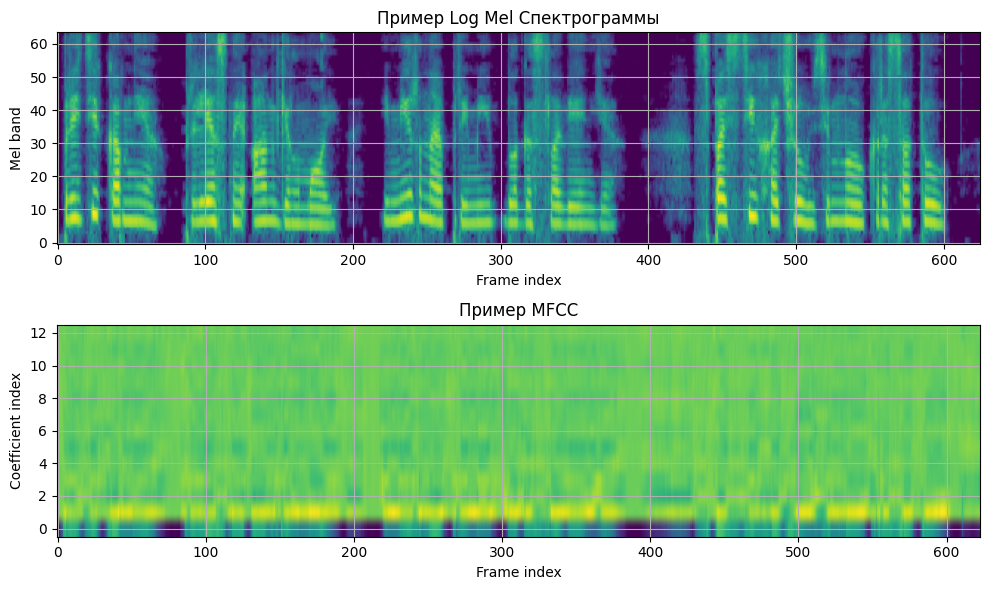

In [ ]:
fig, axes = plt.subplots(2, 1, figsize=(10, 6))

axes[0].imshow(torch.log(mel_spectrogram.clamp(min=1e-5)).cpu().numpy(), aspect='auto', origin='lower')
axes[1].imshow(mfcc_spectrogram.cpu().numpy(), aspect='auto', origin='lower')

axes[0].grid(True)
axes[1].grid(True)

axes[0].set_title('Пример Log Mel Спектрограммы')
axes[1].set_title('Пример MFCC')

axes[0].set_xlabel('Frame index')
axes[1].set_xlabel('Frame index')
axes[0].set_ylabel('Mel band')
axes[1].set_ylabel('Coefficient index')

fig.tight_layout()
plt.show()

### Аугментации

In [ ]:
def display_signal(signal, sample_rate, text=None):
    display(Audio(data=signal.cpu().numpy(), rate=sample_rate))

    fig, ax = plt.subplots(1, 1, figsize=(10, 3))

    ax.plot(np.arange(signal.shape[0]) / sample_rate, signal.cpu().numpy())

    ax.grid(True)
    if text is not None:
        ax.set_title(text)

    ax.set_xlabel('time')
    ax.set_ylabel('magnitude')

    fig.suptitle('Пример аудио сигнала')
    fig.tight_layout()
    plt.show()

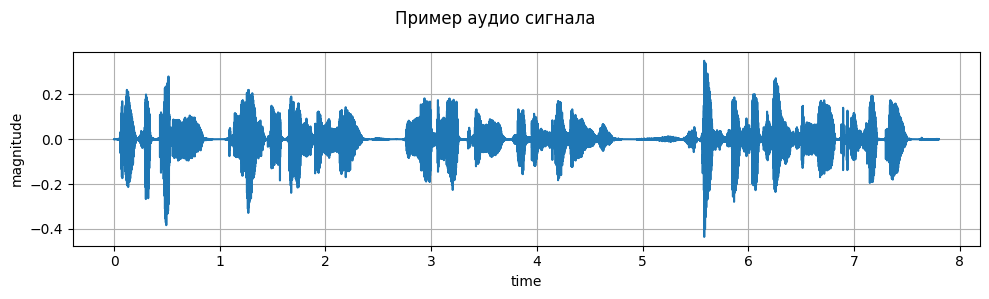

In [ ]:
display_signal(signal, sample_rate)

#### Gaussian Noise

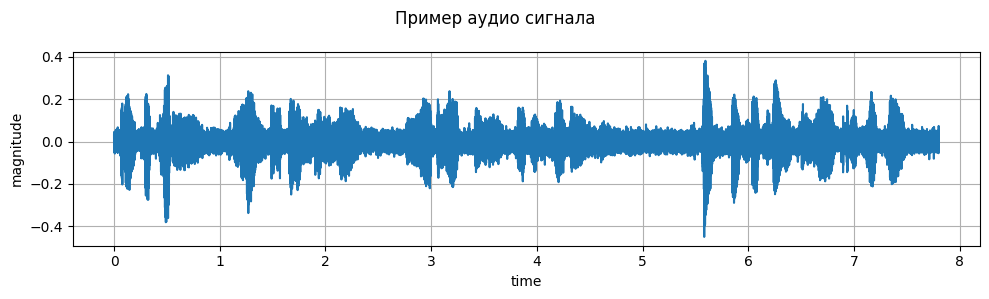

In [ ]:
noiser = torch.distributions.Normal(0, 0.02)
augumented_signal_01 = signal + noiser.sample(signal.size())
display_signal(augumented_signal_01, sample_rate)

#### Time Stretching

Наивный подход:

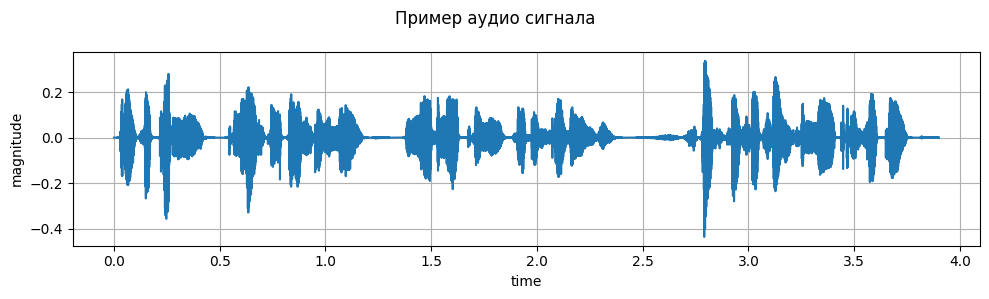

In [ ]:
display_signal(signal[::2], sample_rate)

[Продвинутый подход](https://www.dafx.de/paper-archive/2000/pdf/Bernardini.pdf)
    
Есть два способа сделать Time Stretching:
1. `librosa.effects.time_stretch`, который можно применять напрямую к Wav
2. `torchaudio.transforms.TimeStretch`, который работает со спектрограммами.
    * В этом случае нужно дополнительно использовать `STFT` и `iSTFT` (обратный `STFT`)

In [ ]:
augumented_signal_02 = librosa.effects.time_stretch(signal.numpy().squeeze(), rate=2.0)
augumented_signal_02 = torch.from_numpy(augumented_signal_02)

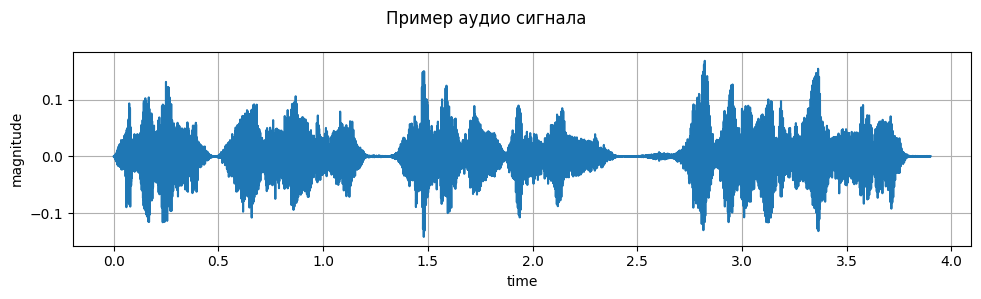

In [ ]:
display_signal(augumented_signal_02, sample_rate)

#### Pitch Shifting

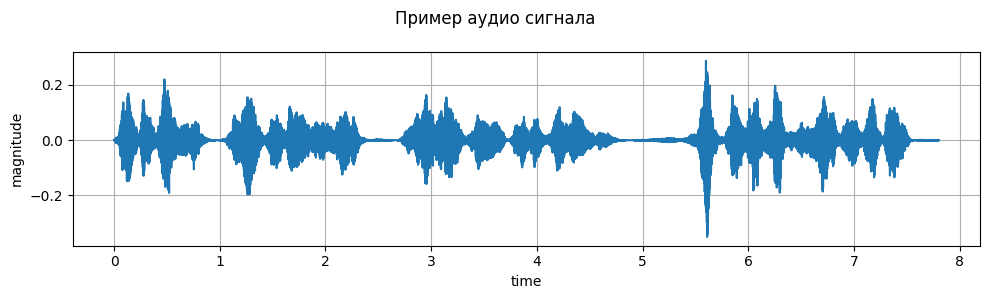

In [ ]:
augumented_signal_03 = librosa.effects.pitch_shift(signal.numpy().squeeze(), n_steps=5, sr=sample_rate)
augumented_signal_03 = torch.from_numpy(augumented_signal_03)
display_signal(augumented_signal_03, sample_rate)

#### SpecAug (Time/Freq masking, Cutout)

Так как спектрограмма по сути является изображением, к ней можно применять аугментации из Computer Vision.

Подробнее можно почитать в статье [SpecAugment: A Simple Data Augmentation Method for Automatic Speech Recognition](https://arxiv.org/pdf/1904.08779.pdf).

In [ ]:
log_mel_spectrogram = torch.log(mel_spectrogram.clamp(min=1e-5))
specaug = torch.nn.Sequential(
    torchaudio.transforms.FrequencyMasking(20),
    torchaudio.transforms.TimeMasking(100),
)
augumented_log_mel_spectrogram = specaug(log_mel_spectrogram.unsqueeze(0)).squeeze(0)

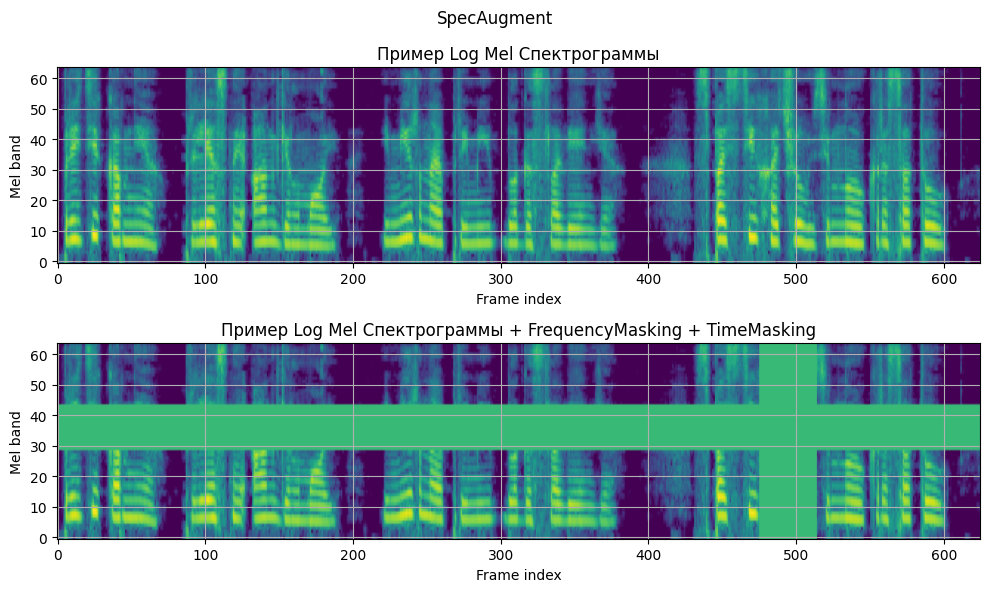

In [ ]:
fig, axes = plt.subplots(2, 1, figsize=(10, 6))

axes[0].imshow(log_mel_spectrogram.cpu().numpy(), aspect='auto', origin='lower')
axes[1].imshow(augumented_log_mel_spectrogram.cpu().numpy(), aspect='auto', origin='lower')

axes[0].grid(True)
axes[1].grid(True)

axes[0].set_title('Пример Log Mel Спектрограммы')
axes[1].set_title('Пример Log Mel Спектрограммы + FrequencyMasking + TimeMasking')

axes[0].set_xlabel('Frame index')
axes[1].set_xlabel('Frame index')
axes[0].set_ylabel('Mel band')
axes[1].set_ylabel('Mel band')

fig.suptitle('SpecAugment')
fig.tight_layout()
plt.show()

## Источники

- [CTC, Graves et al., 2006](https://www.cs.toronto.edu/~graves/icml_2006.pdf).
- [Whisper, Radford et al., 2022](https://arxiv.org/abs/2212.04356).
- [FastSpeech, Ren et al., 2019](https://arxiv.org/abs/1905.09263).
- [WaveGlow, Prenger et al., 2018](https://arxiv.org/abs/1810.00002).
- [Griffin, Lim, 1984](https://doi.org/10.1109/TASSP.1984.1164317).
- [SpecAugment, Park et al., 2019](https://arxiv.org/abs/1904.08779).